# Can depth-crossing dynamics predict κ? (completed 2026-10-21)

**Short answer.** No, not with this instrument. A kernel of milestone-to-milestone crossings fitted at small territories
over-predicts boundary occupation at a 4-16× larger territory by about 2× for most rules (P2 FAILED, all three criteria).
The data show why this had to fail: boundary dwell E[D] is flat over a 4× range of L (log-log slope ≈ 0) and κ is stable, so B/S ∝ 1/L and
any small-size persistence misses by about the L ratio. "E[T] grows linearly with L" (median slope 0.998) is the *same statement* as "κ stable" given that δ ≈ 0:
it follows from the renewal identity, not a mechanism (see Result 2). A kernel fitted at smaller L cannot know the scale. P1, P3 and P4 were first left untested; a registered stage V2 then ran them and each came out **uninformative** for stated reasons (below).
See [README](README.md) for the frozen protocol and [NOTEBOOK](NOTEBOOK.md) for the dated record. This notebook reads only committed `results/`.

## Question, assumptions, what was registered

Renewal–reward: with episodes D (boundary) and T (interior), boundary fraction f = E[D]/(E[D]+E[T]) and κ_inst = (A/P)·f.
The experiment asked whether a finite-state chain over depth milestones 0,1,2,4,…,64 (depth = distance through visited cells to the boundary)
can predict f at a new, larger territory, transfer to unseen rule families, and be insensitive to extra local context.
Assumptions that turned out to matter: (1) maximum-likelihood chains reproduce the empirical mean E[T] in-sample whatever the state partition,
so any gain must be out-of-sample; (2) interior episodes cannot change the territory, so evolving and frozen depth coincide.

In [1]:
import json, subprocess
from pathlib import Path
import numpy as np, polars as pl
R = Path('results') if Path('results').is_dir() else Path('experiments/archive/2026-10-kappa-first-passage/results')
man = json.loads((R/'confirm_manifest.json').read_text())
ana = json.loads((R/'confirm_analysis_skipP3.json').read_text())
des = json.loads((R/'describe.json').read_text())
rd = json.loads((R/'readiness.json').read_text())
c2b = json.loads((R/'calibration_c2b.json').read_text())
pred = pl.read_csv(R/'confirm_predictions.csv')
print('git of notebook run:', subprocess.run(['git','rev-parse','HEAD'],capture_output=True,text=True).stdout.strip())
print('census sha256:', man['source_sha256'][:16], '| cohort git:', man['git'][:10], '| sampler sha256:', rd['sampler_sha256'][:16])
print('rules', man['n_rules'], 'families', len(man['families']), 'runs', man['n_specs'], 'seeds kernel', man['kernel_seeds'][0], '..', man['kernel_seeds'][-1], 'outcome', man['outcome_seeds'][0], '..', man['outcome_seeds'][-1])

git of notebook run: b921066f76aa6862ed8c3d3534e283f6274d468a
census sha256: c76c7927185b1cee | cohort git: e931af26c3 | sampler sha256: 8e0807f002298220
rules 48 families 12 runs 768 seeds kernel 202610208001 .. 202610208008 outcome 202610209001 .. 202610209008


## Instrument checks (what supports trusting the numbers)

In [2]:
print('stop reasons:', ana['stop_counts'], '| depth decreases:', ana['depth_decreases'], '| pair-table overflow:', ana['overflowed'])
print('max unresolved in-band share: %.4f' % ana['unresolved_share_max'])
print('eligible rules: %d / %d' % (ana['eligibility']['n_eligible'], ana['eligibility']['n_rules']))
print('readiness:', {k: v for k, v in rd.items() if k.startswith(('threads','resume','changed'))})
print('calibration (see README): C1 bias -1.7% but seed-bootstrap coverage 0.84 (FAILED); C2 negative control mis-specified (in-sample identity);')
print('  C2b out-of-sample: M0 bias %.1f%%, M1 %.1f%% ; C5 family-bootstrap coverage 0.90-0.92' % (
    100*c2b['C2b']['visible=False,level=M0']['mean_rel_bias'], 100*c2b['C2b']['visible=True,level=M1']['mean_rel_bias']))

stop reasons: {'budget': 32, 'complete': 734, 'escaped': 2} | depth decreases: 0 | pair-table overflow: 0
max unresolved in-band share: 0.0012
eligible rules: 46 / 48
readiness: {'threads_1_vs_4_files_identical_except_status': True, 'threads_1_vs_4_status_without_seconds_identical': True, 'resume_skipped_specs': 5, 'resume_bytes_unchanged': True, 'changed_recipe_refused': True}
calibration (see README): C1 bias -1.7% but seed-bootstrap coverage 0.84 (FAILED); C2 negative control mis-specified (in-sample identity);
  C2b out-of-sample: M0 bias -39.7%, M1 -0.5% ; C5 family-bootstrap coverage 0.90-0.92


## Result 1 — P2 (predictive closure) FAILED

In [3]:
p2 = ana['P2']
print('n rules', p2['n_rules'])
print('median relative error:', {k: round(v,3) for k,v in p2['median_rel_err'].items()})
print('mean abs error:', {k: round(v,4) for k,v in p2['mean_abs_err'].items()})
print('strongest baseline:', p2['strongest_baseline'], '| improvement', round(p2['improvement_mean_abs'],4), 'family-bootstrap CI', [round(x,4) for x in p2['improvement_ci95_family_bootstrap']])
print('criteria:', p2['criteria'], '=>', p2['verdict'])
print('M0/M1/M2 E[T] max relative difference: %.4f' % p2['M0_M1_M2_ET_max_rel_diff'])

n rules 46
median relative error: {'M2': 1.071, 'M0': 1.071, 'M1': 1.071, 'B1_trainmean': 4.118, 'B2_geometry': 6.309, 'B3_persist': 0.986, 'B4_ET_extrap': 0.933}
mean abs error: {'M2': 0.0372, 'M0': 0.0372, 'M1': 0.0372, 'B1_trainmean': 0.0502, 'B2_geometry': 0.0574, 'B3_persist': 0.0277, 'B4_ET_extrap': 0.0365}
strongest baseline: B3_persist | improvement -0.0094 family-bootstrap CI [-0.0234, 0.0009]
criteria: {'median_rel_err_le_0p20': False, 'abs_err_ge_10pct_smaller_than_strongest': False, 'ci_excludes_zero_in_favour': False} => FAIL
M0/M1/M2 E[T] max relative difference: 0.0008


**Shows:** M2 is far from the observed band-2 B/S and worse than simply persisting the band-1 value; M0, M1, M2 are indistinguishable.
**Does not show:** that no local mechanism exists. The depth-64 level carries more than half of the fitted E[T] in 35 of 46 rules, so by the frozen rule
this closure is uninformative about locality.

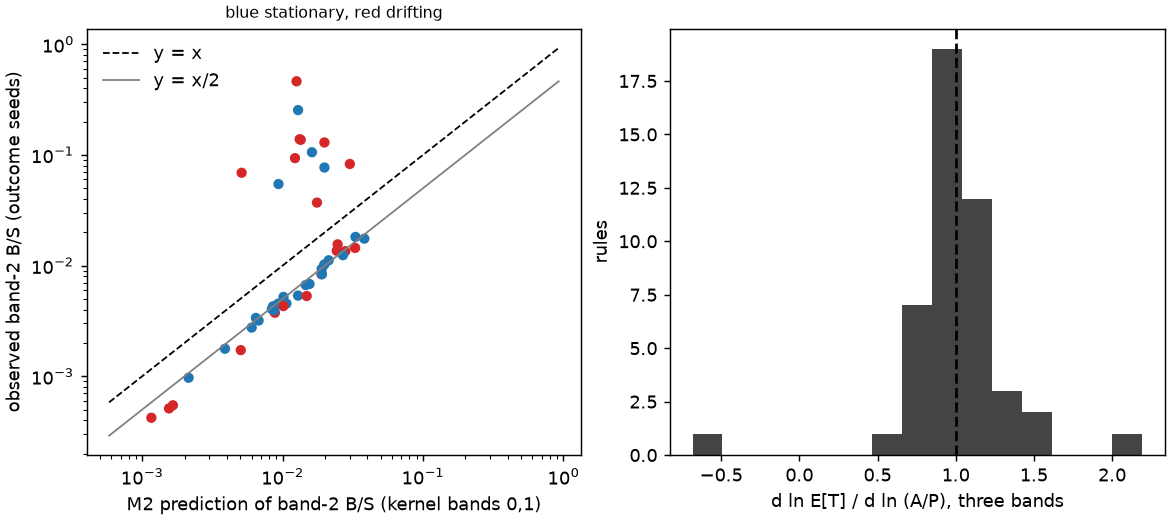

In [4]:
from IPython.display import Image
Image(filename=str(R/'fig_pred_vs_obs.png'))

## Result 2 — what is new (δ ≈ 0) and what is only the renewal identity (post hoc, descriptive)

In [5]:
for k in ['slope_lnED_on_lnL','slope_lnET_on_lnL','slope_lnkappa_on_lnL']:
    print(k, dict(zip(['p10','p25','p50','p75','p90'], [round(x,3) for x in des[k]['quantiles_10_25_50_75_90']])), 'n', des[k]['n'])
print('renewal identity 1+delta-slope_ET (medians): %.3f vs measured d ln kappa / d ln L (median): %.3f' % (des['identity_median_lhs'], des['identity_median_rhs']))
print('obs/pred B/S quantiles:', [round(x,2) for x in des['obs_over_pred_ratio_quantiles_10_25_50_75_90']])
print('predicted/observed E[T] quartiles:', [round(x,2) for x in ana['P2']['ET_pred_over_obs_quartiles']])
ir = des['identity_residual_per_rule']
print('per-rule residual of slope_ET - (1+slope_ED-slope_kappa): |res| median/p90/max =', [round(x,3) for x in ir['abs_quantiles_50_90_max']], '| median band-2 B/S', round(ir['median_band2_BS'],4))
kp = des['kappa_persistence_exploratory']
print('exploratory geometry-conditional kappa persistence: median rel err %.3f, mean abs err %.4f (M2 %.4f, band-1 B/S persistence %.4f)' % (kp['median_rel_err'], kp['mean_abs_err'], kp['vs_M2_mean_abs_err'], kp['vs_B3_persistence_mean_abs_err']))

slope_lnED_on_lnL {'p10': -0.006, 'p25': -0.003, 'p50': -0.001, 'p75': 0.004, 'p90': 0.011} n 46
slope_lnET_on_lnL {'p10': 0.793, 'p25': 0.876, 'p50': 0.998, 'p75': 1.104, 'p90': 1.335} n 46
slope_lnkappa_on_lnL {'p10': -0.387, 'p25': -0.113, 'p50': -0.003, 'p75': 0.135, 'p90': 0.946} n 46
renewal identity 1+delta-slope_ET (medians): 0.002 vs measured d ln kappa / d ln L (median): -0.003
obs/pred B/S quantiles: [0.39, 0.44, 0.48, 1.74, 8.9]
predicted/observed E[T] quartiles: [0.42, 0.45, 0.49]
per-rule residual of slope_ET - (1+slope_ED-slope_kappa): |res| median/p90/max = [0.036, 0.909, 1.57] | median band-2 B/S 0.0083
exploratory geometry-conditional kappa persistence: median rel err 0.097, mean abs err 0.0206 (M2 0.0372, band-1 B/S persistence 0.0277)


**Shows:** across 46 rules the boundary dwell E[D] does not grow with L (δ ≈ 0) over a 4× range, which *is* new. Because B/S is 0.005–0.05, f ≈ E[D]/E[T], and then ln κ = ln L + ln E[D] − ln E[T] is bookkeeping: "E[T] ∝ L" and "κ stable" are the same statement given δ ≈ 0, and the 1+δ−slope check is an identity (median residual 0.036, but up to 1.6 for rules whose B/S is not small).
**Does not show:** any mechanism for why E[T] tracks L. A later tail fit (stage V2) failed its calibration, so P1 is uninformative and its exponents are not reported. The best null the design lacked is exploratory κ persistence (own band-1 κ times band-2 P/A), which is within ~10% for the median rule but is geometry-conditional.
The 26% of rules with obs/pred > 2 were *not* inspected as a class (some, e.g. B/S 0.46, may be highway onsets rather than blob drift).

## Stage V2: P1, P3, P4 run, all uninformative; checkpoint gate met

In [6]:
p1 = json.loads((R/'p1_test.json').read_text()); p3 = json.loads((R/'p3_pooled.json').read_text()); p4 = json.loads((R/'p4_test.json').read_text())
c6 = json.loads((R/'calibration_c6.json').read_text()); rc = json.loads((R/'resume_check.json').read_text())
print('V2-A checkpoint: killed after %ss, checkpoint %d bytes, resumed=%s, outputs identical=%s' % (rc['killed_after_seconds'], rc['checkpoint_bytes'], rc['resumed_from_checkpoint'], rc['all_files_identical_except_status_seconds']))
print('P1 C6: max|bias theta| %.3f, max|bias ln tau| %.3f (needs <0.2), pooled coverage %.3f (needs 0.90-0.99), pass=%s' % (c6['max_abs_bias_theta'], c6['max_abs_bias_ln_tau'], c6['pooled_coverage_theta'], c6['pass']))
s64 = p1['by_t0']['64']
print('P1 identifiable %d/%d; median theta %.2f, median z %.2f; median |pred-obs| %.3f vs zero-drift %.3f ->' % (s64['n_identifiable'], s64['n_eligible'], s64['median_theta'], s64['median_z'], s64['median_abs_err'], s64['median_zero_drift_err']), p1['verdict_main_t0_64'])
print('P3 pooled R2:', {k: round(v,3) for k,v in p3['r2'].items()}, 'gain M2-M0 %.1e' % p3['gain_M2_over_M0'], '->', p3['verdict'][:13])
print('P4 median supported share %.3f (needs 0.30) ->' % p4['median_supported_share'], p4['verdict'])
print('(P2 frozen verdict unchanged:', ana['P2']['verdict'] + ')')
print('non-complete runs:', des['non_complete_runs_by_rule'])

V2-A checkpoint: killed after 1.5s, checkpoint 7874790 bytes, resumed=True, outputs identical=True
P1 C6: max|bias theta| 0.015, max|bias ln tau| 0.238 (needs <0.2), pooled coverage 0.893 (needs 0.90-0.99), pass=False
P1 identifiable 33/46; median theta 0.54, median z 2.20; median |pred-obs| 0.094 vs zero-drift 0.109 -> UNINFORMATIVE (calibration C6 failed) (fewer than 80% of eligible rules identifiable)
P3 pooled R2: {'M0': -0.132, 'M1': -0.132, 'M2': -0.132} gain M2-M0 1.7e-07 -> UNINFORMATIVE
P4 median supported share 0.005 (needs 0.30) -> UNINFORMATIVE (median supported share below 0.30)
(P2 frozen verdict unchanged: FAIL)
non-complete runs: [{'rule': 'RLRLLLL', 'stratum': 'drifting', 'stop': 'budget', 'runs': 16}, {'rule': 'RRRRRRLLLLLL', 'stratum': 'drifting', 'stop': 'budget', 'runs': 16}, {'rule': 'RRRRRRRLR', 'stratum': 'stationary', 'stop': 'escaped', 'runs': 2}]


## Caveats
- Pilot predictions were inspected before the confirmation freeze (disclosed in NOTEBOOK.md); no threshold changed.
- The tail fit failed its calibration, so its θ and z are not reported as findings (z is built from τ, the parameter with the worst bias). P3/P4 are uninformative by structure/sparsity, not evidence for or against.
- Seed-bootstrap intervals under-cover (C1: 84% for nominal 95%); decisions use family bootstrap (C5: 90–92%).
- Two drifting rules never reached band 2 within 2^32 steps (32 runs) and RRRRRRRLR escaped the board twice: the drifting stratum is censored.
- Analysis reproducible to ~1e-15, not bitwise (polars aggregation order); the full analysis' exploratory P3 block was skipped for runtime (disclosed).

## Next steps
Make the tail estimator pass C6 (more data per rule-band or a better-conditioned cutoff parameter) and test z(1−θ)=1+δ then; test E[T] ∝ L at larger bands on new starts; add deeper milestones (> 64) and radius-4 context to the recorder; design a state variable the kernel can intervene on (README stage 4).